# DSCI 552, Homework 6

Name: Ivan Sun  
GitHub Username: peterlololsss

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from xgboost import XGBClassifier

### (a) Download the APS Failure data

In [2]:
train_data = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_data = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")
print("Training set size:", train_data.shape)
print("Test set size:", test_data.shape)

Training set size: (60000, 171)
Test set size: (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common ways to deal with missing values are deleting the rows or columns that contain them, filling each feature with its mean, median or mode, k-nearest-neighbor imputation, regression or iterative imputation (MICE), which predicts a feature from the other features, model-based methods such as the EM algorithm, and adding an indicator variable that marks the missing entries. In this data 99% of the training rows have at least one missing value, so deleting rows would leave almost nothing. I use median imputation, with the training medians for the training set and the test medians for the test set, since most of the features are heavily skewed and the median is not pulled by the extreme values.

In [3]:
features = [c for c in train_data.columns if c != "class"]
print("Fraction of training rows with a missing value:", round(train_data[features].isna().any(axis=1).mean(), 4))

X_train = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(train_data[features]), columns=features)
X_test = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(test_data[features]), columns=features)
y_train = (train_data["class"] == "pos").astype(int).values
y_test = (test_data["class"] == "pos").astype(int).values

Fraction of training rows with a missing value: 0.9902


#### (ii) Calculate the coefficient of variation

In [4]:
cv_values = X_train.std() / X_train.mean()
cv_values = cv_values.sort_values(ascending=False)
print(cv_values.round(4).to_string())

cf_000    244.8875
co_000    244.5074
ad_000    244.3228
cs_009    237.9306
dh_000    123.2161
dj_000    117.4942
ag_000     92.9178
as_000     87.3325
ay_009     84.7337
ak_000     80.4250
az_009     77.8385
ch_000     77.4539
au_000     68.8828
cr_000     58.0781
ay_001     52.8247
df_000     52.2928
dz_000     51.3322
ef_000     49.3667
cs_008     48.1022
aj_000     44.2660
eg_000     42.4817
dl_000     39.7391
ay_002     39.2487
dg_000     38.4862
ay_000     37.4283
dk_000     37.0391
cy_000     36.6009
dm_000     36.2614
ag_001     35.2493
ea_000     34.9465
cn_009     34.2721
ay_004     33.7523
ag_009     33.3576
da_000     29.3675
ay_003     28.7351
cn_000     26.3356
ae_000     24.2001
at_000     23.7082
az_008     22.6797
dq_000     22.0301
af_000     19.4713
ai_000     18.2038
ag_002     17.5659
az_007     16.2294
cl_000     14.9707
cz_000     14.5056
cp_000     13.9333
az_002     13.2717
ay_005     12.5247
di_000     11.8262
ar_000     11.3543
cn_001     11.2626
cj_000     1

#### (iii) Plot a correlation matrix

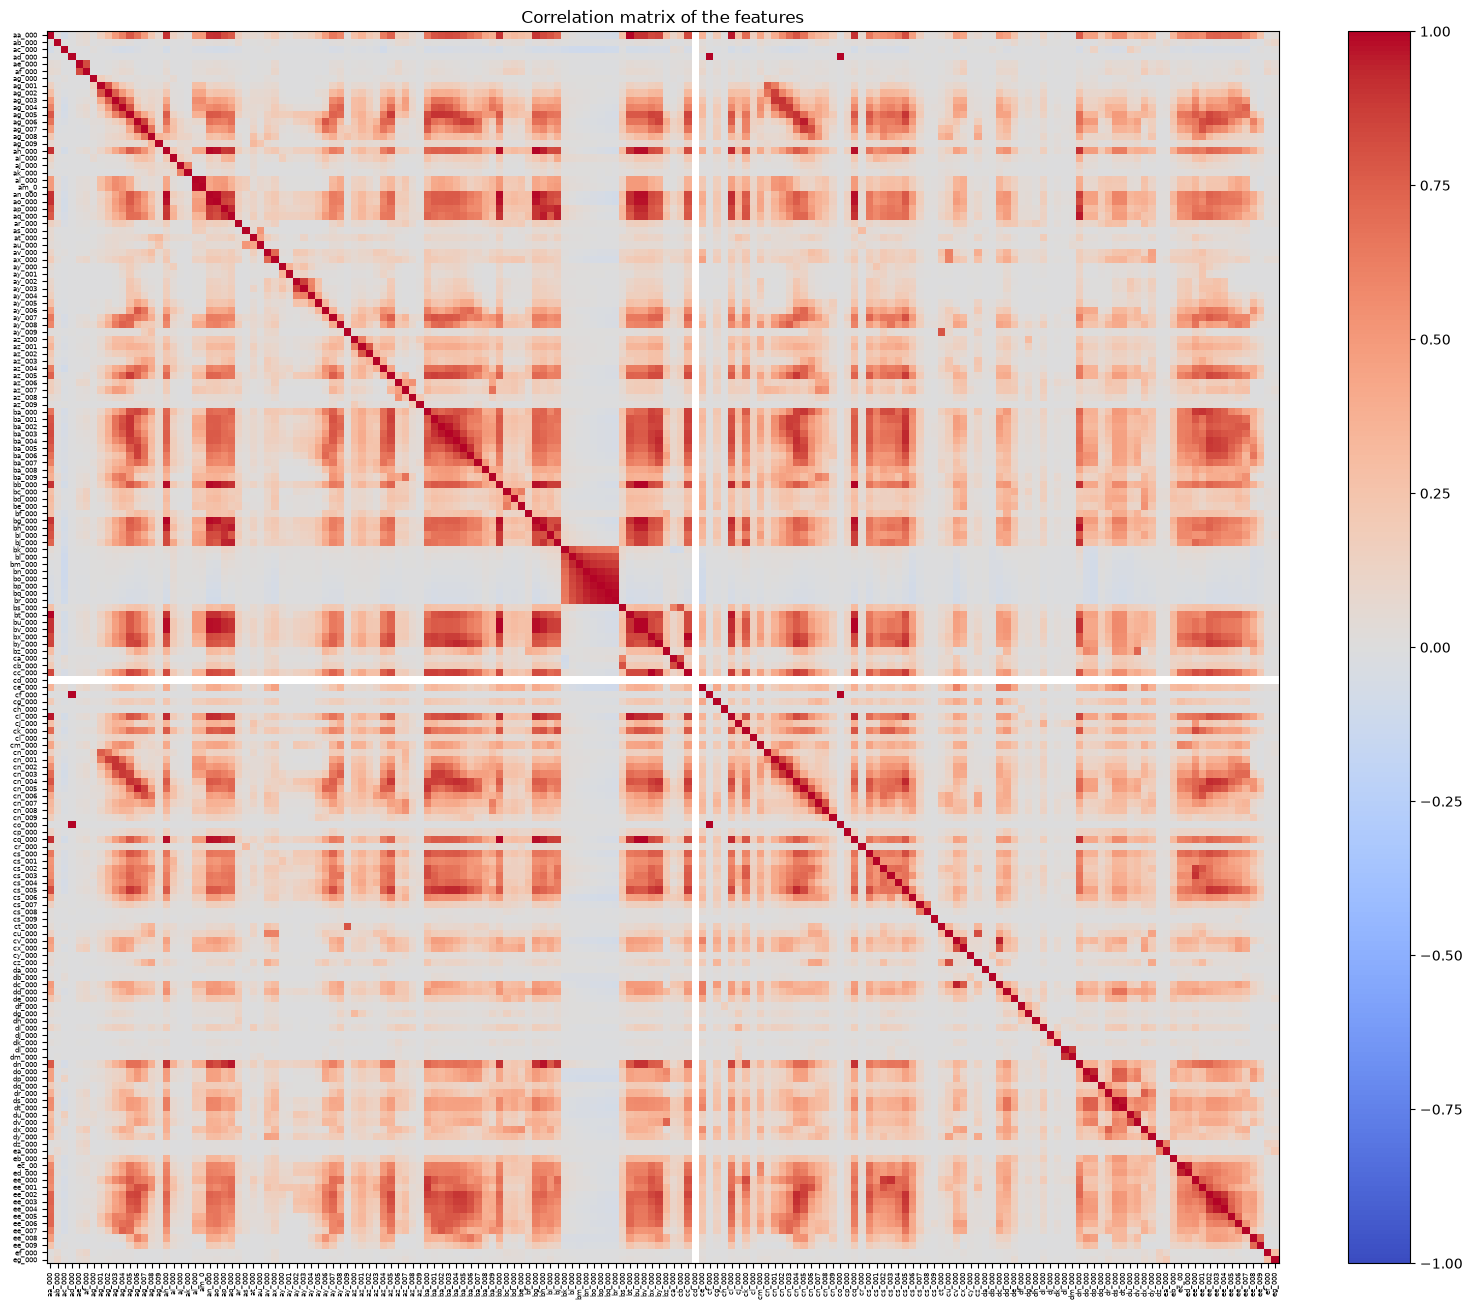

In [5]:
corr = X_train.corr()

plt.figure(figsize=(18, 16))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(fraction=0.046)
plt.xticks(range(len(features)), features, rotation=90, fontsize=5)
plt.yticks(range(len(features)), features, fontsize=5)
plt.title("Correlation matrix of the features")
plt.show()

#### (iv) Make scatter plots and box plots

Features with highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


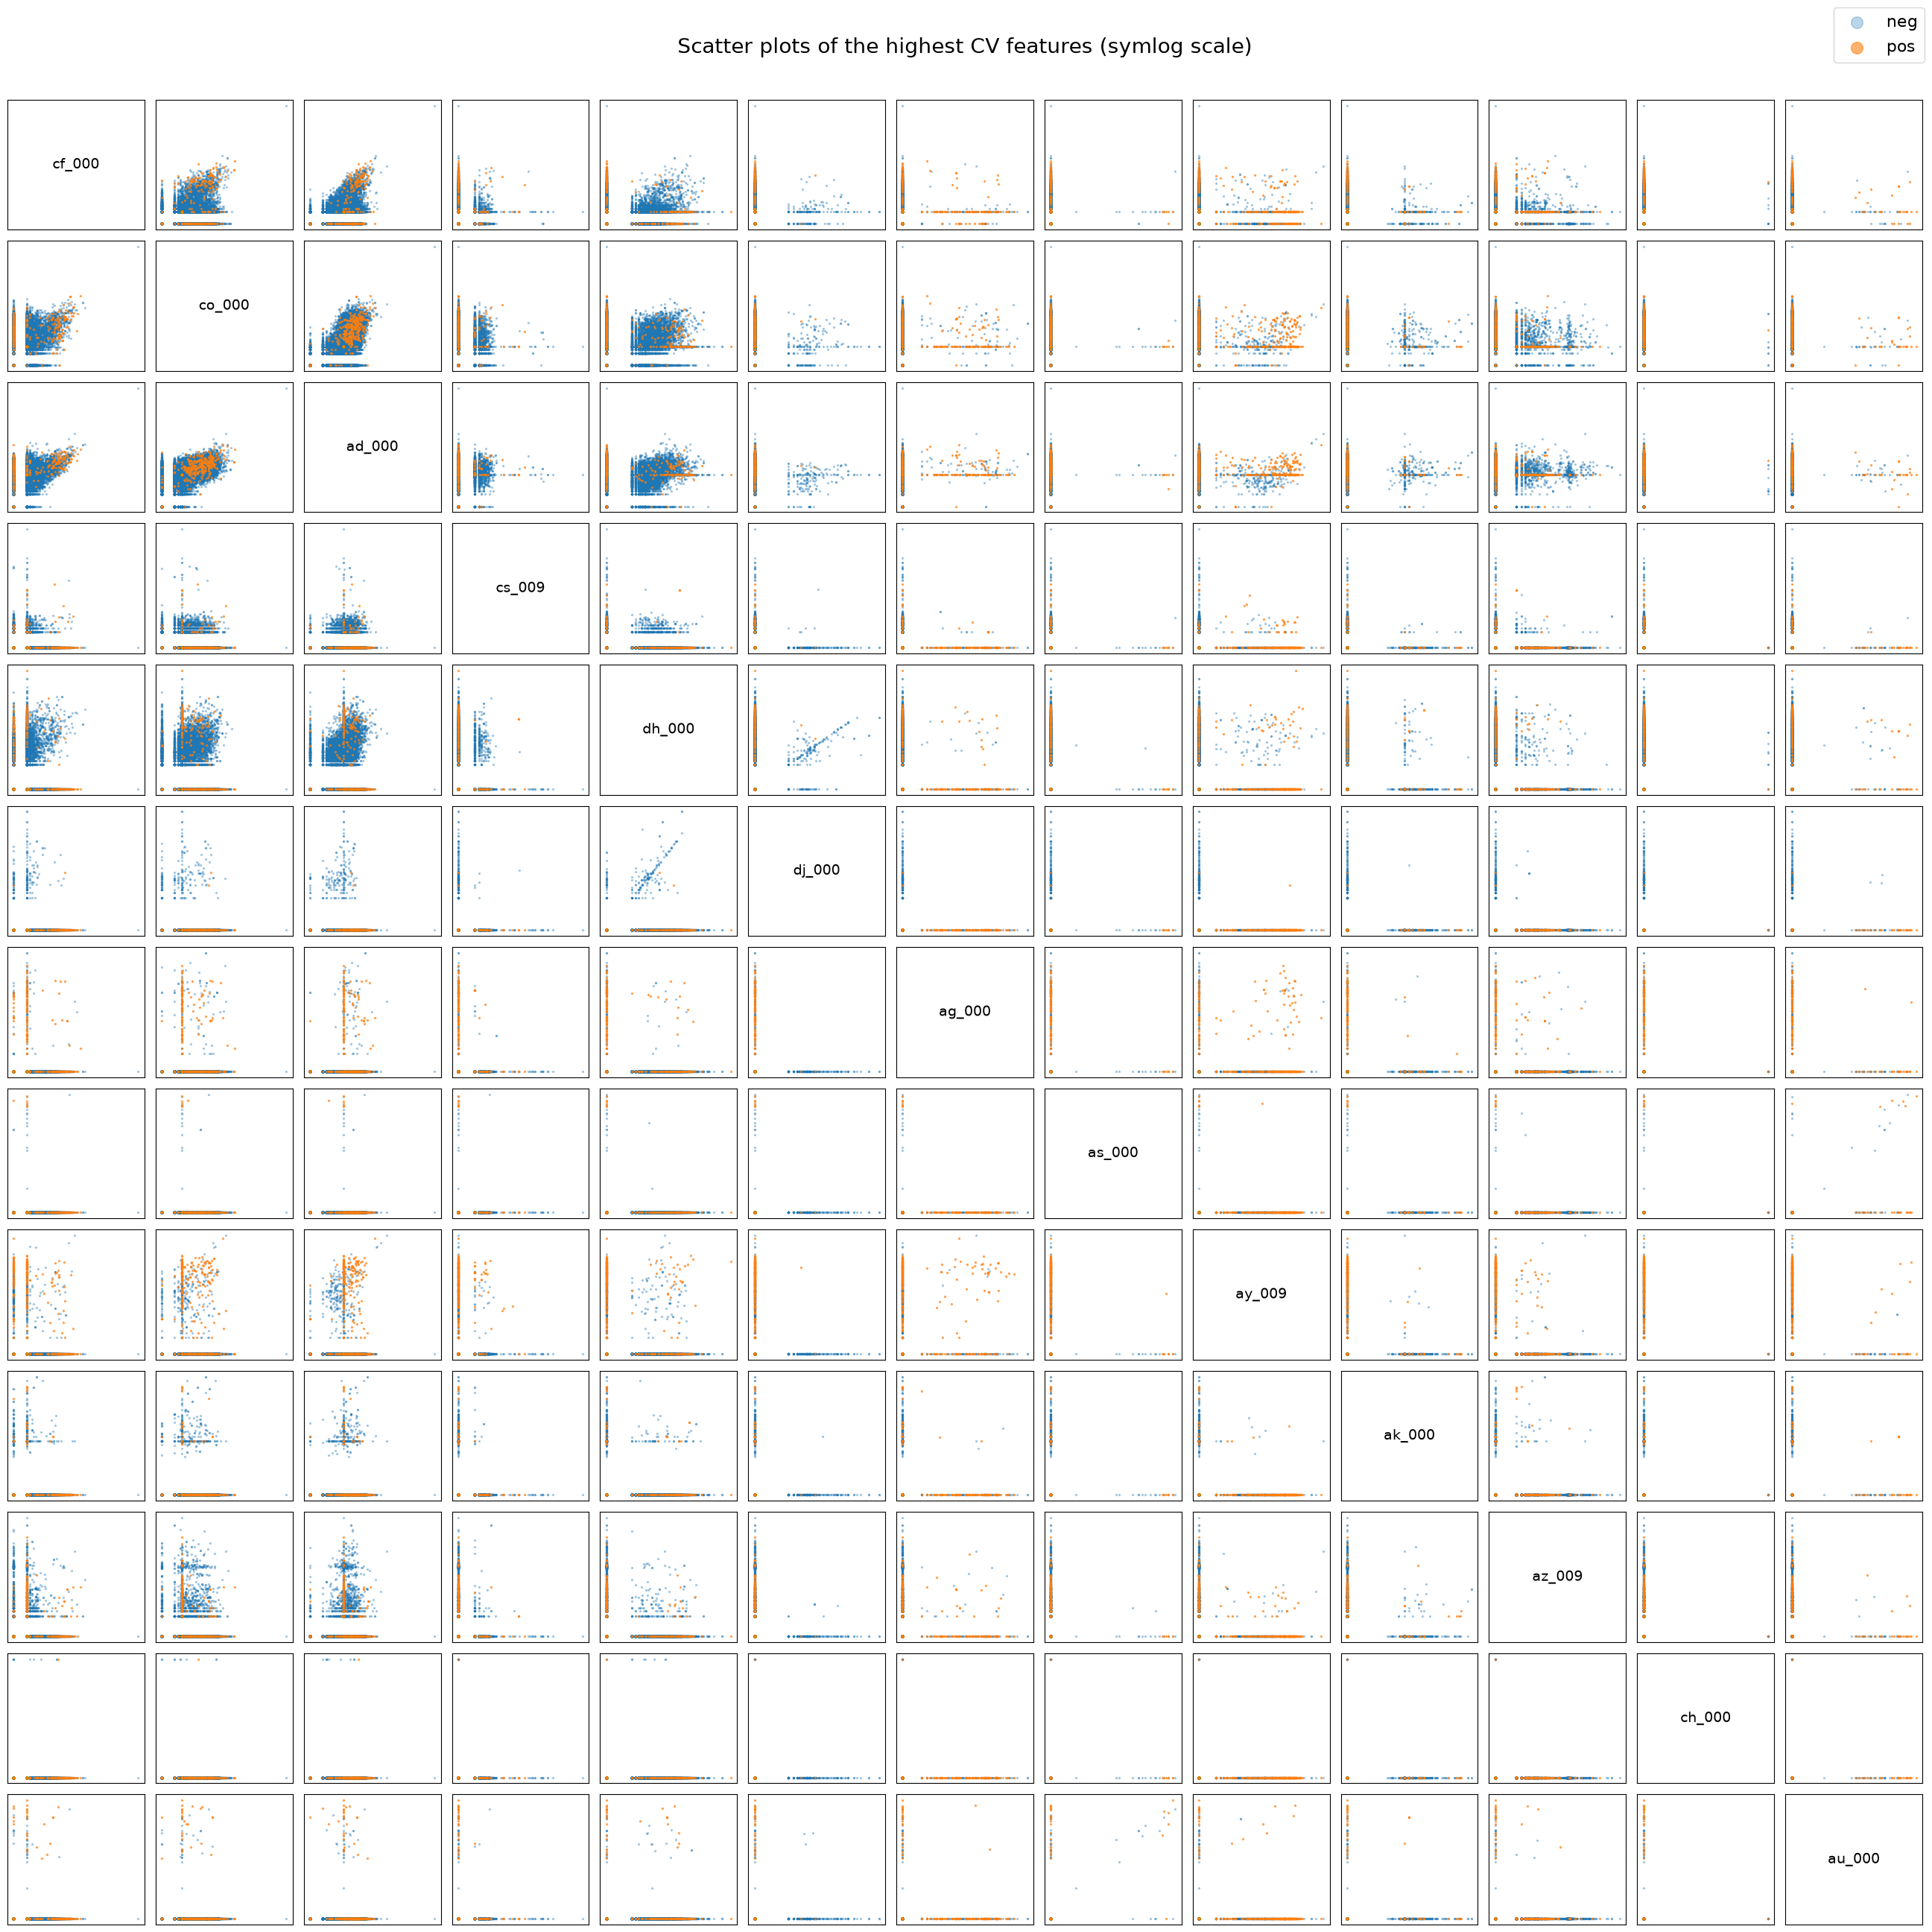

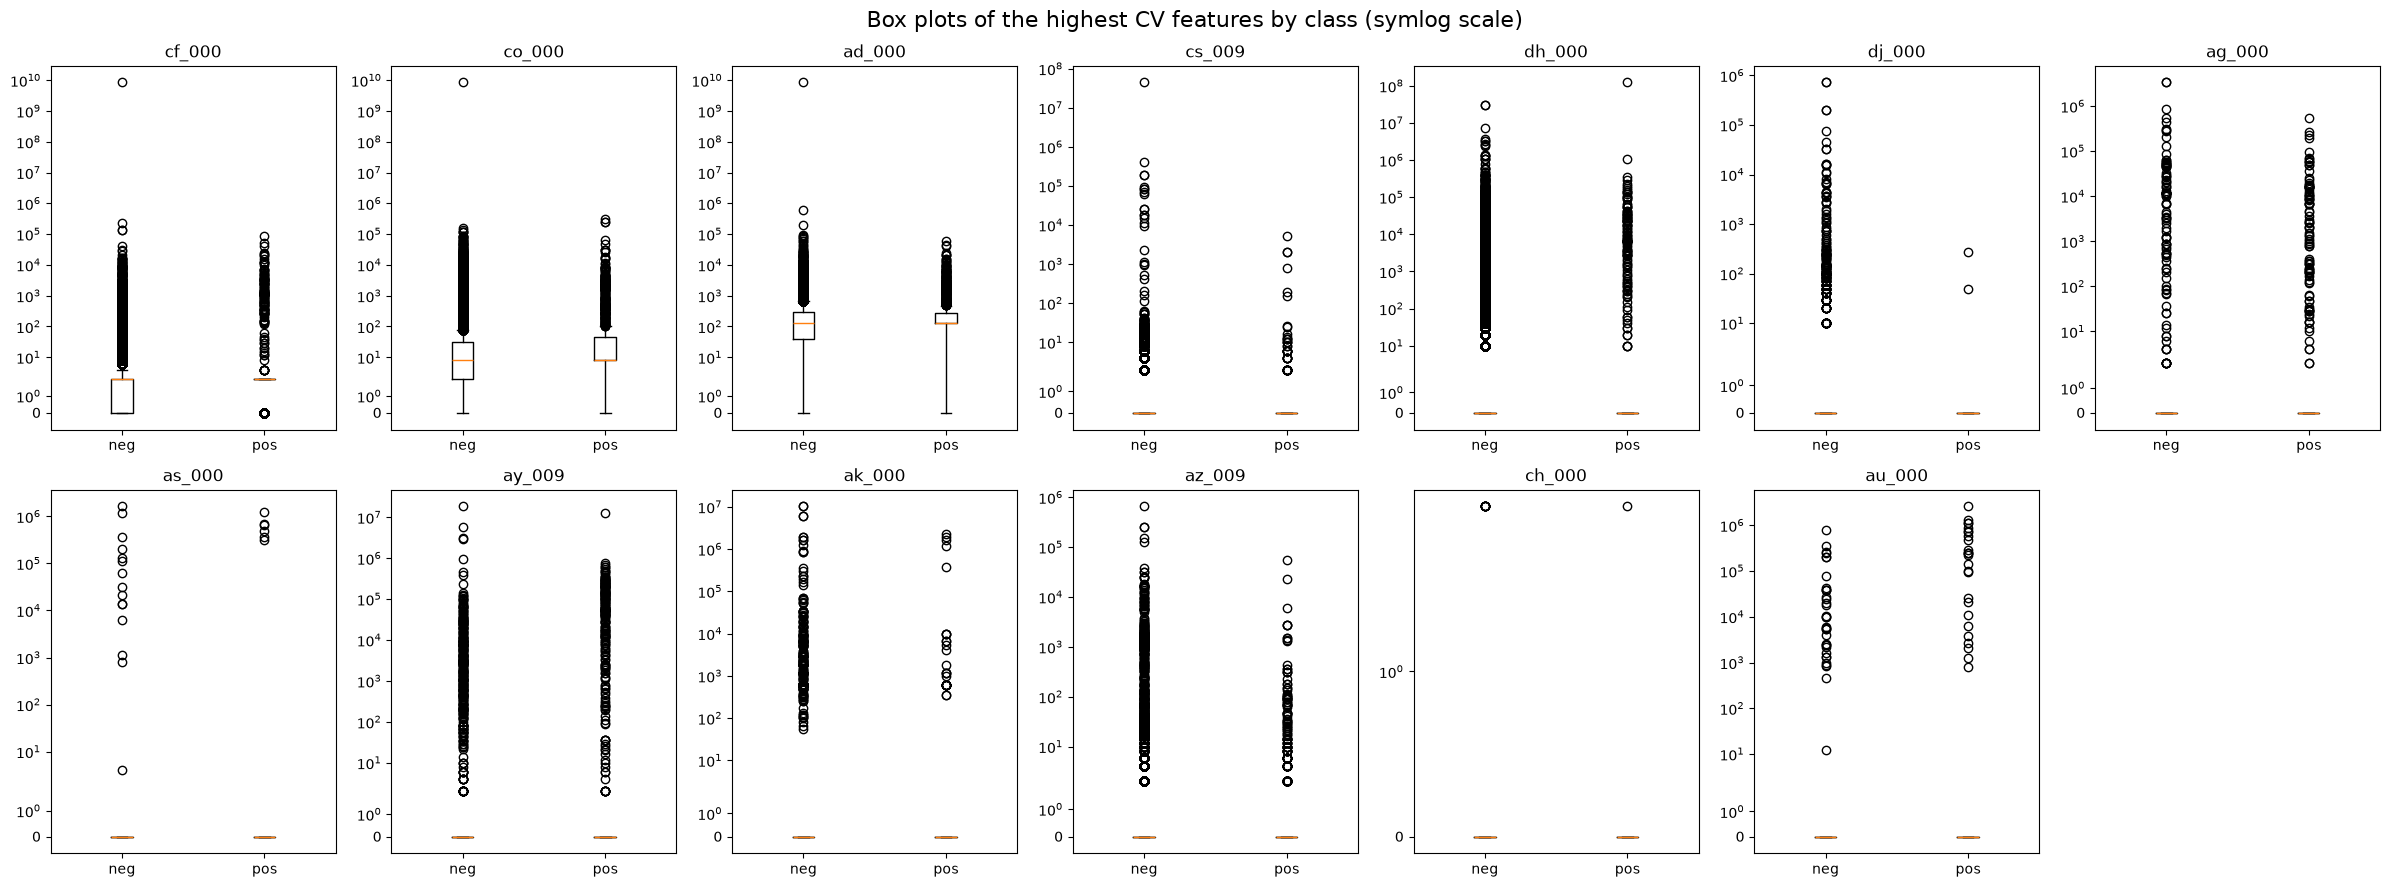

In [6]:
k = int(np.floor(np.sqrt(170)))
top_features = list(cv_values.index[:k])
print("Features with highest CV:", top_features)

neg = X_train[y_train == 0]
pos = X_train[y_train == 1]

fig, axes = plt.subplots(k, k, figsize=(26, 26))
for i in range(k):
    for j in range(k):
        ax = axes[i, j]
        if i == j:
            ax.text(0.5, 0.5, top_features[i], ha="center", va="center", fontsize=14)
        else:
            ax.scatter(neg[top_features[j]], neg[top_features[i]], s=2, c="tab:blue", alpha=0.3, label="neg")
            ax.scatter(pos[top_features[j]], pos[top_features[i]], s=2, c="tab:orange", alpha=0.6, label="pos")
            ax.set_xscale("symlog")
            ax.set_yscale("symlog")
        ax.set_xticks([])
        ax.set_yticks([])
        ax.minorticks_off()
handles, labels = axes[0, 1].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", markerscale=8, fontsize=16)
plt.suptitle("Scatter plots of the highest CV features (symlog scale)", fontsize=20)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

fig, axes = plt.subplots(2, 7, figsize=(24, 9))
for ax, f in zip(axes.flatten(), top_features):
    ax.boxplot([neg[f], pos[f]], tick_labels=["neg", "pos"])
    ax.set_yscale("symlog")
    ax.set_title(f)
axes[1, 6].axis("off")
plt.suptitle("Box plots of the highest CV features by class (symlog scale)", fontsize=16)
plt.tight_layout()
plt.show()

No. In the cf_000, co_000 and ad_000 panels the positive trucks sit toward larger values, and in ag_000 and ay_009 the positive trucks have nonzero values more often, so some of these features may help. The two classes still overlap in every panel, and a scatter plot shows two features at a time with no formal test, so the plots alone cannot tell me which features are significant. That needs a fitted model with tests on the coefficients or a variable importance measure.

#### (v) Is this data set imbalanced?

In [7]:
print("Training set:")
print(train_data["class"].value_counts())
print()
print("Test set:")
print(test_data["class"].value_counts())

Training set:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test set:
class
neg    15625
pos      375
Name: count, dtype: int64


Yes. The training set has 59000 negative and 1000 positive trucks, so only 1.67% of the training data is positive. The test set has 15625 negative and 375 positive trucks (2.34% positive).

### (c) Train a random forest

OOB error estimate: 0.00582



Training confusion matrix:
          pred neg  pred pos
true neg     59000         0
true pos         0      1000
Training misclassification rate: 0.0
Training AUC: 1.0



Test confusion matrix:
          pred neg  pred pos
true neg     15606        19
true pos       104       271
Test misclassification rate: 0.00769
Test AUC: 0.99435



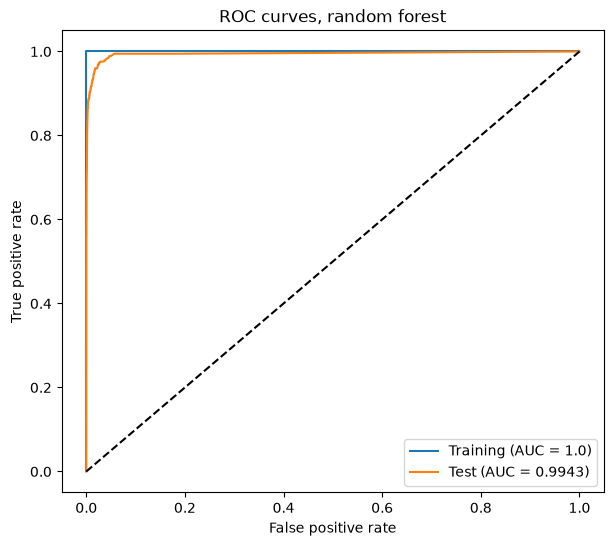

In [8]:
def evaluate(model, X_train, y_train, X_test, y_test, title):
    plt.figure(figsize=(7, 6))
    for name, X, y in [("Training", X_train, y_train), ("Test", X_test, y_test)]:
        y_pred = model.predict(X)
        y_score = model.predict_proba(X)[:, 1]
        auc = roc_auc_score(y, y_score)
        print(name, "confusion matrix:")
        print(pd.DataFrame(confusion_matrix(y, y_pred), index=["true neg", "true pos"], columns=["pred neg", "pred pos"]))
        print(name, "misclassification rate:", round(1 - accuracy_score(y, y_pred), 5))
        print(name, "AUC:", round(auc, 5))
        print()
        fpr, tpr, _ = roc_curve(y, y_score)
        plt.plot(fpr, tpr, label=name + " (AUC = " + str(round(auc, 4)) + ")")
    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False positive rate")
    plt.ylabel("True positive rate")
    plt.title("ROC curves, " + title)
    plt.legend()
    plt.show()


rf = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1, random_state=552)
rf.fit(X_train, y_train)
print("OOB error estimate:", round(1 - rf.oob_score_, 5))
print()
evaluate(rf, X_train, y_train, X_test, y_test, "random forest")

The forest fits the training set perfectly (misclassification rate 0.0, AUC 1.0). On the test set the misclassification rate is 0.00769 and the AUC is 0.99435, and 104 of the 375 failed trucks are classified as negative. The OOB error estimate is 0.00582, a little below the test error of 0.00769. Almost all the test errors are missed positives, and the test set is 2.34% positive against 1.67% in the training set, which accounts for most of the gap.

### (d) Research class imbalance in random forest

Chen, Liaw and Breiman (2004) give two ways to handle class imbalance in a random forest. A weighted random forest puts a larger weight on the minority class, both in the Gini criterion used to choose the splits and in the vote at the terminal nodes. A balanced random forest grows each tree on a balanced sample: a bootstrap sample from the minority class and a sample of the same size drawn with replacement from the majority class. The data can also be resampled before training (undersampling the majority class or oversampling the minority class, for example with SMOTE), and the probability cutoff for the positive class can be lowered.

I use the balanced random forest from imbalanced-learn, so each tree is grown on 1000 positive and 1000 negative trucks.

OOB error estimate: 0.04372



Training confusion matrix:
          pred neg  pred pos
true neg     56461      2539
true pos         0      1000
Training misclassification rate: 0.04232
Training AUC: 0.99831



Test confusion matrix:
          pred neg  pred pos
true neg     14979       646
true pos         7       368
Test misclassification rate: 0.04081
Test AUC: 0.99318



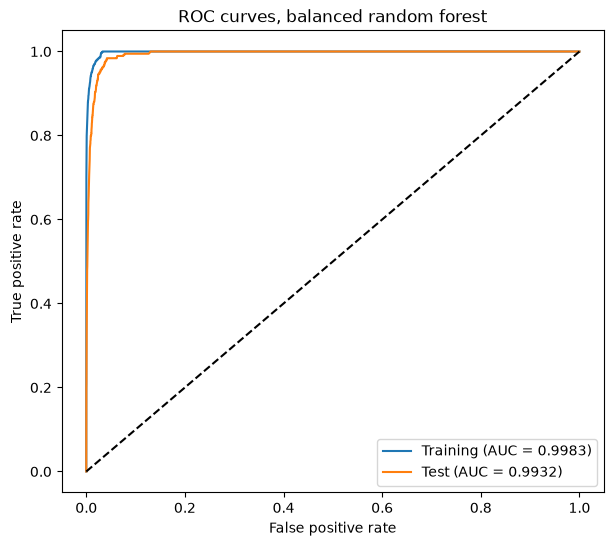

In [9]:
brf = BalancedRandomForestClassifier(n_estimators=500, sampling_strategy="all", replacement=True, bootstrap=False, n_jobs=-1, random_state=552)
brf.fit(X_train, y_train)

oob_sum = np.zeros(len(y_train))
oob_count = np.zeros(len(y_train))
for sampler, tree in zip(brf.samplers_, brf.estimators_):
    oob = np.ones(len(y_train), dtype=bool)
    oob[sampler.sample_indices_] = False
    oob_sum[oob] += tree.predict_proba(X_train.values[oob])[:, 1]
    oob_count[oob] += 1
oob_pred = (oob_sum / oob_count > 0.5).astype(int)
print("OOB error estimate:", round(np.mean(oob_pred != y_train), 5))
print()
evaluate(brf, X_train, y_train, X_test, y_test, "balanced random forest")

The balanced forest finds many more failed trucks than the forest in 1(c): on the test set it misses 7 of the 375 positives, against 104. The cost is 646 false positives on the test set against 19, so the test misclassification rate rises from 0.00769 to 0.04081 and the OOB error from 0.00582 to 0.04372. The test AUC barely changes (0.99318 against 0.99435), so both forests rank the trucks about equally well and the balancing mainly moves the decision boundary toward the positive class. The OOB error of 0.04372 is again close to the test error of 0.04081.

### (e) XGBoost and Model Trees

Best alpha: 0.1
5-fold CV error: 0.00563



Training confusion matrix:
          pred neg  pred pos
true neg     59000         0
true pos         2       998
Training misclassification rate: 3e-05
Training AUC: 0.99998

Test confusion matrix:
          pred neg  pred pos
true neg     15608        17
true pos        83       292
Test misclassification rate: 0.00625
Test AUC: 0.99504



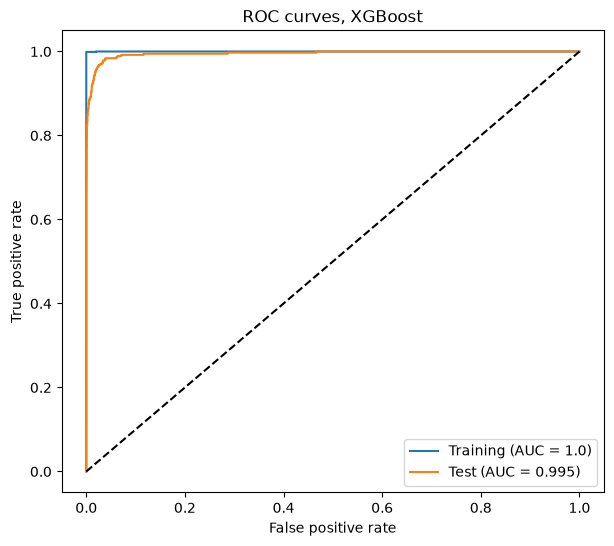

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=552)
alpha_values = [0, 0.01, 0.1, 0.5, 1, 5, 10, 100]

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, random_state=552, n_jobs=1)
xgb_grid = GridSearchCV(xgb, {"reg_alpha": alpha_values}, cv=cv, scoring="accuracy", n_jobs=-1)
xgb_grid.fit(X_train, y_train)
print("Best alpha:", xgb_grid.best_params_["reg_alpha"])
print("5-fold CV error:", round(1 - xgb_grid.best_score_, 5))
print()
evaluate(xgb_grid.best_estimator_, X_train, y_train, X_test, y_test, "XGBoost")

Cross-validation picks $\alpha = 0.1$. The 5-fold CV error is 0.00563 and the test error is 0.00625, so the CV estimate is close to the test error and a little lower. On the test set the model misses 83 of the 375 positives, has 17 false positives and reaches an AUC of 0.99504.

### (f) Use SMOTE to pre-process your data

Class counts after SMOTE: [59000 59000]


Best alpha: 0.01
5-fold CV error: 0.00683



Training confusion matrix:
          pred neg  pred pos
true neg     58997         3
true pos        12       988
Training misclassification rate: 0.00025
Training AUC: 0.99995

Test confusion matrix:
          pred neg  pred pos
true neg     15541        84
true pos        51       324
Test misclassification rate: 0.00844
Test AUC: 0.99446



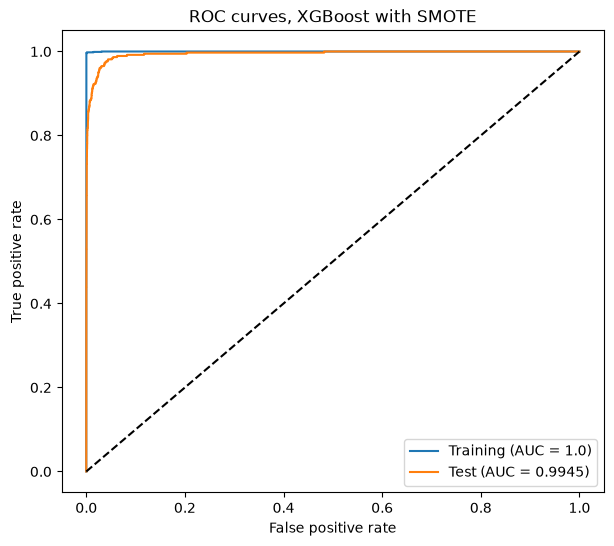

In [11]:
X_smote, y_smote = SMOTE(random_state=552).fit_resample(X_train, y_train)
print("Class counts after SMOTE:", np.bincount(y_smote))

smote_pipe = Pipeline([("smote", SMOTE(random_state=552)), ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.1, random_state=552, n_jobs=1))])
smote_grid = GridSearchCV(smote_pipe, {"xgb__reg_alpha": alpha_values}, cv=cv, scoring="accuracy", n_jobs=4, refit=False)
smote_grid.fit(X_train, y_train)
best_alpha = smote_grid.best_params_["xgb__reg_alpha"]
print("Best alpha:", best_alpha)
print("5-fold CV error:", round(1 - smote_grid.best_score_, 5))
print()

xgb_smote = XGBClassifier(n_estimators=200, learning_rate=0.1, reg_alpha=best_alpha, random_state=552, n_jobs=-1)
xgb_smote.fit(X_smote, y_smote)
evaluate(xgb_smote, X_train, y_train, X_test, y_test, "XGBoost with SMOTE")

SMOTE runs inside each training fold of the cross-validation, so no validation fold holds synthetic points built from its own positives, which would make the CV error too optimistic.

Cross-validation picks $\alpha = 0.01$. Compared with the uncompensated model in 1(e), the SMOTE model catches more failures on the test set (324 of 375 against 292) and raises more false alarms (84 against 17). The test misclassification rate goes from 0.00625 to 0.00844 and the CV error from 0.00563 to 0.00683, while the test AUC stays about the same (0.99446 against 0.99504). SMOTE gives better detection of the positive class at the price of a slightly higher overall error.

## 2. ISLR 6.6.3

As $s$ increases from 0, the constraint $\sum_{j=1}^p |\beta_j| \le s$ gets looser. At $s = 0$ every $\beta_j$ is 0 and the model predicts $\bar{y}$ for every observation. Once $s$ is large enough, the lasso solution is the least squares solution.

**(a)** iv. Steadily decrease. A larger $s$ gives a larger feasible set, so the minimized training RSS can only go down, and it stops at the least squares RSS.

**(b)** ii. Decrease initially, and then eventually start increasing in a U shape. For small $s$ the model is too restricted, and the drop in bias lowers the test RSS. For large $s$ the coefficients start to fit noise in the training data, and the growing variance raises the test RSS.

**(c)** iii. Steadily increase. At $s = 0$ the fit does not depend on the training predictors and the variance is smallest. As $s$ grows the coefficients depend more on the particular training set.

**(d)** iv. Steadily decrease. The model becomes more flexible as $s$ grows, so it can get closer to the true relationship.

**(e)** v. Remain constant. The irreducible error $\text{Var}(\epsilon)$ does not depend on the model or on $s$.

## 3. ISLR 6.6.5

**(a)** With $\hat{\beta}_0 = 0$, ridge regression minimizes

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(\beta_1^2 + \beta_2^2).$$

**(b)** Since $x_{11} = x_{12}$ and $x_{21} = x_{22}$, the objective is

$$f(\beta_1, \beta_2) = \left(y_1 - (\beta_1 + \beta_2)x_{11}\right)^2 + \left(y_2 - (\beta_1 + \beta_2)x_{21}\right)^2 + \lambda(\beta_1^2 + \beta_2^2).$$

Setting the partial derivatives to zero gives

$$\frac{\partial f}{\partial \beta_1} = -2x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) - 2x_{21}\left(y_2 - (\beta_1 + \beta_2)x_{21}\right) + 2\lambda\beta_1 = 0,$$

$$\frac{\partial f}{\partial \beta_2} = -2x_{11}\left(y_1 - (\beta_1 + \beta_2)x_{11}\right) - 2x_{21}\left(y_2 - (\beta_1 + \beta_2)x_{21}\right) + 2\lambda\beta_2 = 0.$$

The first two terms are the same in both equations, so subtracting them gives $2\lambda(\beta_1 - \beta_2) = 0$. For $\lambda > 0$ this means $\hat{\beta}_1 = \hat{\beta}_2$. The objective is strictly convex when $\lambda > 0$, so this stationary point is the unique minimum.

**(c)** The lasso minimizes

$$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda(|\beta_1| + |\beta_2|).$$

**(d)** Using $x_{11} = x_{12}$, $x_{21} = x_{22} = -x_{11}$ and $y_2 = -y_1$ (and assuming $x_{11} \neq 0$), the RSS depends on the coefficients only through $S = \beta_1 + \beta_2$:

$$f(\beta_1, \beta_2) = 2(y_1 - S x_{11})^2 + \lambda(|\beta_1| + |\beta_2|).$$

By the triangle inequality $|\beta_1| + |\beta_2| \ge |S|$, with equality when $\beta_1$ and $\beta_2$ have the same sign or one of them is 0. For a fixed $S$ the smallest objective is therefore $2(y_1 - S x_{11})^2 + \lambda|S|$, a one-variable lasso problem with the single solution

$$\hat{S} = \text{sign}\left(\frac{y_1}{x_{11}}\right)\max\left(\left|\frac{y_1}{x_{11}}\right| - \frac{\lambda}{4x_{11}^2},\ 0\right).$$

When $\hat{S} \neq 0$, every pair with $\hat{\beta}_1 + \hat{\beta}_2 = \hat{S}$ and both coefficients of the same sign as $\hat{S}$ reaches this minimum. The lasso solutions are the whole line segment

$$\left\{(\beta_1, \beta_2) : \beta_1 + \beta_2 = \hat{S},\ \beta_1 \hat{S} \ge 0,\ \beta_2 \hat{S} \ge 0\right\},$$

which is one edge of the diamond $|\beta_1| + |\beta_2| = |\hat{S}|$. In the constraint form, the RSS contours are the lines $\beta_1 + \beta_2 = c$, parallel to that edge of the lasso diamond, so the smallest contour that meets the diamond meets it along a whole edge.

## 4. ISLR 8.4.5

**Majority vote:** 6 of the 10 estimates (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, so 6 trees vote Red and 4 vote Green. The final class is **Red**.

**Average probability:** $\frac{0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = \frac{4.5}{10} = 0.45 < 0.5$, so the final class is **Green**.

## 5. ISLR 9.7.3

#### (a)

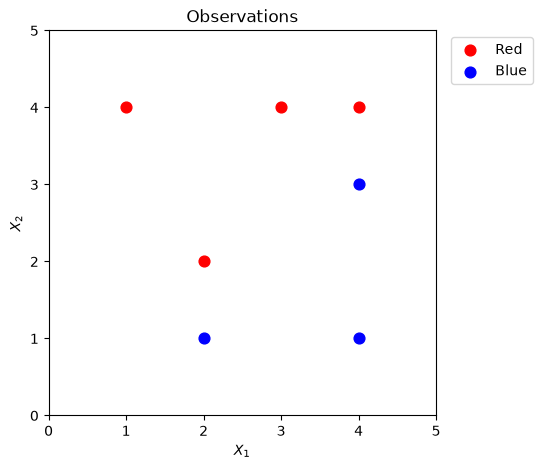

In [12]:
X1 = np.array([3, 2, 4, 1, 2, 4, 4])
X2 = np.array([4, 2, 4, 4, 1, 3, 1])
Y = np.array(["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"])

plt.figure(figsize=(5, 5))
plt.scatter(X1[Y == "Red"], X2[Y == "Red"], c="red", s=60, label="Red")
plt.scatter(X1[Y == "Blue"], X2[Y == "Blue"], c="blue", s=60, label="Blue")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Observations")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

#### (b)

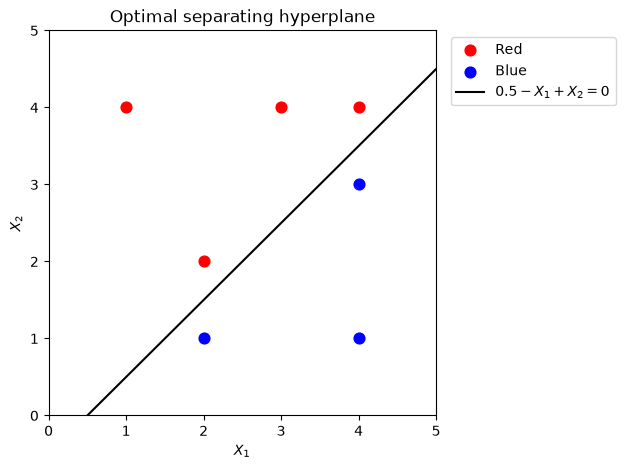

In [13]:
x = np.linspace(0, 5, 100)

plt.figure(figsize=(5, 5))
plt.scatter(X1[Y == "Red"], X2[Y == "Red"], c="red", s=60, label="Red")
plt.scatter(X1[Y == "Blue"], X2[Y == "Blue"], c="blue", s=60, label="Blue")
plt.plot(x, x - 0.5, "k-", label="$0.5 - X_1 + X_2 = 0$")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Optimal separating hyperplane")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

The maximal margin hyperplane lies halfway between the parallel lines $X_2 = X_1$, through the Red points (2, 2) and (4, 4), and $X_2 = X_1 - 1$, through the Blue points (2, 1) and (4, 3). It passes through (2, 1.5) and (4, 3.5), so it is $X_2 = X_1 - 0.5$, or in the form of (9.1)

$$0.5 - X_1 + X_2 = 0.$$

#### (c)

Classify to Red if $0.5 - X_1 + X_2 > 0$, and classify to Blue otherwise, so $\beta_0 = 0.5$, $\beta_1 = -1$ and $\beta_2 = 1$. With the normalization $\beta_1^2 + \beta_2^2 = 1$ these become $\beta_0 = 0.354$, $\beta_1 = -0.707$ and $\beta_2 = 0.707$.

#### (d) and (e)

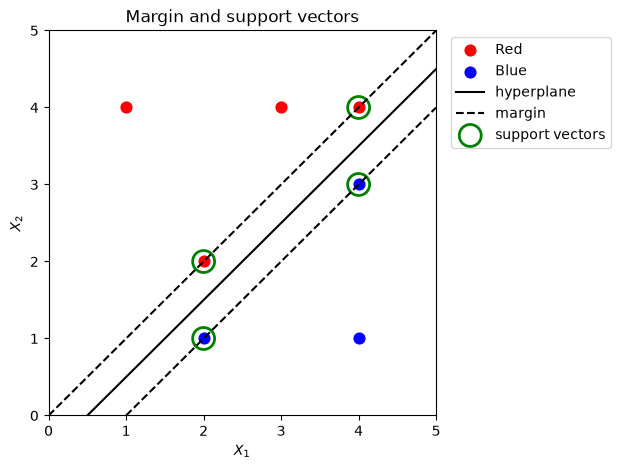

In [14]:
plt.figure(figsize=(5, 5))
plt.scatter(X1[Y == "Red"], X2[Y == "Red"], c="red", s=60, label="Red")
plt.scatter(X1[Y == "Blue"], X2[Y == "Blue"], c="blue", s=60, label="Blue")
plt.plot(x, x - 0.5, "k-", label="hyperplane")
plt.plot(x, x, "k--", label="margin")
plt.plot(x, x - 1, "k--")
plt.scatter([2, 4, 2, 4], [2, 4, 1, 3], s=250, facecolors="none", edgecolors="green", linewidths=2, label="support vectors")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Margin and support vectors")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

**(d)** The margin is the distance from the hyperplane to the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$:

$$M = \frac{|0.5 - 2 + 2|}{\sqrt{1^2 + 1^2}} = \frac{0.5}{\sqrt{2}} = 0.354.$$

**(e)** The support vectors are observations 2 (2, 2) and 3 (4, 4) from Red and observations 5 (2, 1) and 6 (4, 3) from Blue, circled in green.

#### (f)

Observation 7 at (4, 1) is not a support vector. Its distance to the hyperplane is $|0.5 - 4 + 1|/\sqrt{2} = 1.77$, far outside the margin of 0.354. The maximal margin hyperplane depends only on the support vectors, so a small move of observation 7 that keeps it outside the margin leaves the hyperplane unchanged.

#### (g)

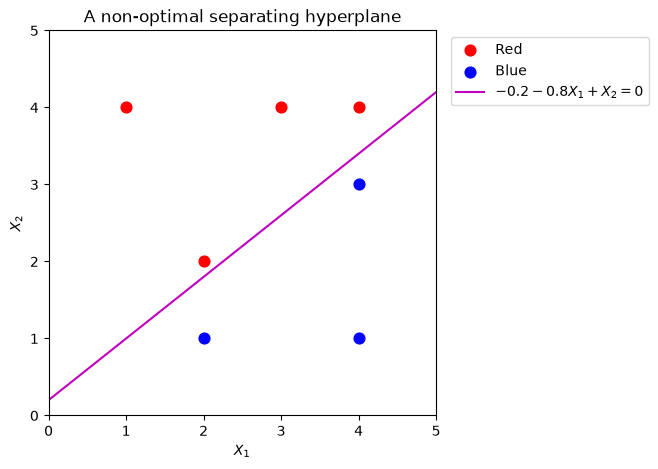

In [15]:
plt.figure(figsize=(5, 5))
plt.scatter(X1[Y == "Red"], X2[Y == "Red"], c="red", s=60, label="Red")
plt.scatter(X1[Y == "Blue"], X2[Y == "Blue"], c="blue", s=60, label="Blue")
plt.plot(x, 0.8 * x + 0.2, "m-", label="$-0.2 - 0.8X_1 + X_2 = 0$")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("A non-optimal separating hyperplane")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

The line $-0.2 - 0.8X_1 + X_2 = 0$ separates the two classes (Red where the left side is positive). It passes close to observation 2 at (2, 2), at a distance of $0.2/\sqrt{0.8^2 + 1^2} = 0.156$, so its margin is smaller than 0.354 and it is not the optimal separating hyperplane.

#### (h)

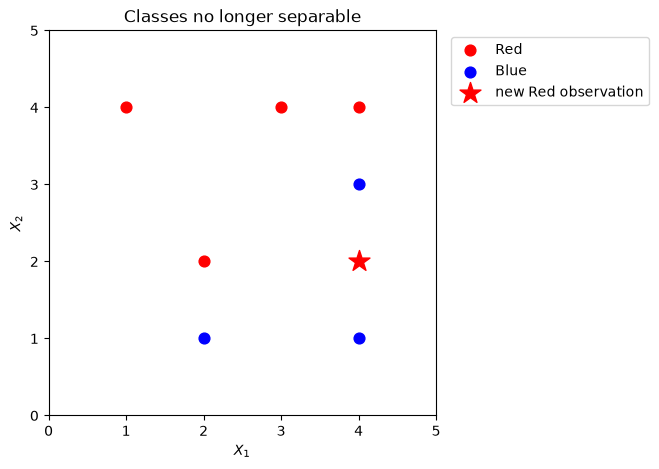

In [16]:
plt.figure(figsize=(5, 5))
plt.scatter(X1[Y == "Red"], X2[Y == "Red"], c="red", s=60, label="Red")
plt.scatter(X1[Y == "Blue"], X2[Y == "Blue"], c="blue", s=60, label="Blue")
plt.scatter([4], [2], c="red", marker="*", s=250, label="new Red observation")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("Classes no longer separable")
plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
plt.show()

The new Red observation at (4, 2) lies on the segment between the Blue observations (4, 1) and (4, 3). Any line with both of these Blue points on one side also has (4, 2) on that side, so no hyperplane can separate the two classes.